# Lab 9 — Building ML Models for EEG Seizure Recognition
**AI in Healthcare · Unit II: Clinical applications of AI**

This notebook implements Parts A–F of the supplied lab. It loads the Kaggle CSV, creates a binary target, splits by recording ID, compares raw-signal and engineered-feature models, selects a threshold on validation data, evaluates the selected model once on the test set, and performs error analysis.

**Dataset source:** https://www.kaggle.com/datasets/harunshimanto/epileptic-seizure-recognition  
**Important:** this is an educational exercise, not a diagnostic tool. Model outputs must not be used for clinical decisions.

## Cell 1 — Imports and reproducibility

In [1]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay
)
from sklearn.calibration import CalibrationDisplay

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
print("Imports complete. Random seed:", SEED)

Imports complete. Random seed: 42


## Cell 2 — Locate and load the CSV
The Kaggle input path may contain a nested directory. This cell searches the specified dataset directory for CSV files.

In [2]:
DATA_DIR = "/kaggle/input/datasets/harunshimanto/epileptic-seizure-recognition"

# Fallback for environments mounting the dataset directly under /kaggle/input.
if not os.path.exists(DATA_DIR):
    DATA_DIR = "/kaggle/input/epileptic-seizure-recognition"

csv_files = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
if not csv_files:
    raise FileNotFoundError(
        f"No CSV found under {DATA_DIR}. Check the dataset path in the Kaggle sidebar."
    )

print("CSV files found:", csv_files)
csv_path = next(
    (p for p in csv_files
     if "epileptic seizure recognition" in os.path.basename(p).lower()),
    csv_files[0]
)
df = pd.read_csv(csv_path)
print("Loaded:", csv_path)
print("Shape:", df.shape)
display(df.head())

CSV files found: ['/kaggle/input/datasets/harunshimanto/epileptic-seizure-recognition/Epileptic Seizure Recognition.csv']
Loaded: /kaggle/input/datasets/harunshimanto/epileptic-seizure-recognition/Epileptic Seizure Recognition.csv
Shape: (11500, 180)


,Unnamed,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,X21.V1.791,135,190,229,223,192,125,55,-9,-33,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,4
1,X15.V1.924,386,382,356,331,320,315,307,272,244,...,164,150,146,152,157,156,154,143,129,1
2,X8.V1.1,-32,-39,-47,-37,-32,-36,-57,-73,-85,...,57,64,48,19,-12,-30,-35,-35,-36,5
3,X16.V1.60,-105,-101,-96,-92,-89,-95,-102,-100,-87,...,-82,-81,-80,-77,-85,-77,-72,-69,-65,5
4,X20.V1.54,-9,-65,-98,-102,-78,-48,-16,0,-21,...,4,2,-12,-32,-41,-65,-83,-89,-73,5


## Part A — Data checks and target definition

### Cell 3 — Check columns, missing values, duplicates, and original labels

In [3]:
print("Columns:", df.columns.tolist())
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

if "y" not in df.columns:
    raise ValueError("Target column 'y' was not found.")
if "Unnamed" not in df.columns:
    raise ValueError("Expected recording identifier column 'Unnamed' was not found.")

signal_cols = [f"X{i}" for i in range(1, 179)]
missing_cols = [c for c in signal_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing expected signal columns: {missing_cols}")

print("\nOriginal label counts:")
display(df["y"].value_counts().sort_index().rename("count").to_frame())
print("\nOriginal label percentages:")
display((df["y"].value_counts(normalize=True).sort_index() * 100)
        .round(2).rename("percentage").to_frame())

Columns: ['Unnamed', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'X24', 'X25', 'X26', 'X27', 'X28', 'X29', 'X30', 'X31', 'X32', 'X33', 'X34', 'X35', 'X36', 'X37', 'X38', 'X39', 'X40', 'X41', 'X42', 'X43', 'X44', 'X45', 'X46', 'X47', 'X48', 'X49', 'X50', 'X51', 'X52', 'X53', 'X54', 'X55', 'X56', 'X57', 'X58', 'X59', 'X60', 'X61', 'X62', 'X63', 'X64', 'X65', 'X66', 'X67', 'X68', 'X69', 'X70', 'X71', 'X72', 'X73', 'X74', 'X75', 'X76', 'X77', 'X78', 'X79', 'X80', 'X81', 'X82', 'X83', 'X84', 'X85', 'X86', 'X87', 'X88', 'X89', 'X90', 'X91', 'X92', 'X93', 'X94', 'X95', 'X96', 'X97', 'X98', 'X99', 'X100', 'X101', 'X102', 'X103', 'X104', 'X105', 'X106', 'X107', 'X108', 'X109', 'X110', 'X111', 'X112', 'X113', 'X114', 'X115', 'X116', 'X117', 'X118', 'X119', 'X120', 'X121', 'X122', 'X123', 'X124', 'X125', 'X126', 'X127', 'X128', 'X129', 'X130', 'X131', 'X132', 'X133', 'X134', 'X135', 'X136',

,count
y,
1,2300
2,2300
3,2300
4,2300
5,2300



Original label percentages:


,percentage
y,
1,20.0
2,20.0
3,20.0
4,20.0
5,20.0


### Cell 4 — Extract recording ID and construct the binary target

In [4]:
# Example identifier: X21.V1.791
# The prefix before the first dot is the chunk number; the remainder identifies the recording.
df["recording_id"] = df["Unnamed"].astype(str).str.split(".", n=1).str[1]
df["seizure"] = (df["y"] == 1).astype(int)

print("Unique recordings:", df["recording_id"].nunique())
print("\nRows per recording (count of recordings with each group size):")
display(df.groupby("recording_id").size().value_counts().sort_index().rename("recordings").to_frame())

labels_per_recording = df.groupby("recording_id")["y"].nunique()
print("\nNumber of distinct labels within each recording:")
display(labels_per_recording.value_counts().sort_index().rename("recordings").to_frame())

print("\nBinary target counts:")
display(df["seizure"].value_counts().sort_index().rename("rows").to_frame())
print(f"Positive seizure rows: {df['seizure'].sum():,}/{len(df):,} "
      f"({df['seizure'].mean()*100:.2f}%)")

assert df["recording_id"].notna().all(), "Missing recording IDs detected."
assert labels_per_recording.eq(1).all(), "At least one recording has multiple labels."

Unique recordings: 500

Rows per recording (count of recordings with each group size):


,recordings
23,500



Number of distinct labels within each recording:


,recordings
y,
1,500



Binary target counts:


,rows
seizure,
0,9200
1,2300


Positive seizure rows: 2,300/11,500 (20.00%)


**Part A questions — written answers**

- **One row:** one segment containing 178 ordered signal values, approximately one second long.
- **One recording:** the original EEG recording, represented by 23 segments in this dataset.
- **One person:** the individual whose EEG was recorded. Patient identifiers are not provided, so recording IDs cannot guarantee person-level independence.
- **Always predicting non-seizure:** accuracy is the proportion of non-seizure rows (approximately 80% in this dataset). It detects no seizure rows, so accuracy alone is misleading.
- **Why 20% is not real-world prevalence:** this dataset has a constructed class distribution and selected recordings; it does not represent the prevalence of seizure segments in routine clinical EEG review.

### Cell 5 — Plot two example segments for each original label

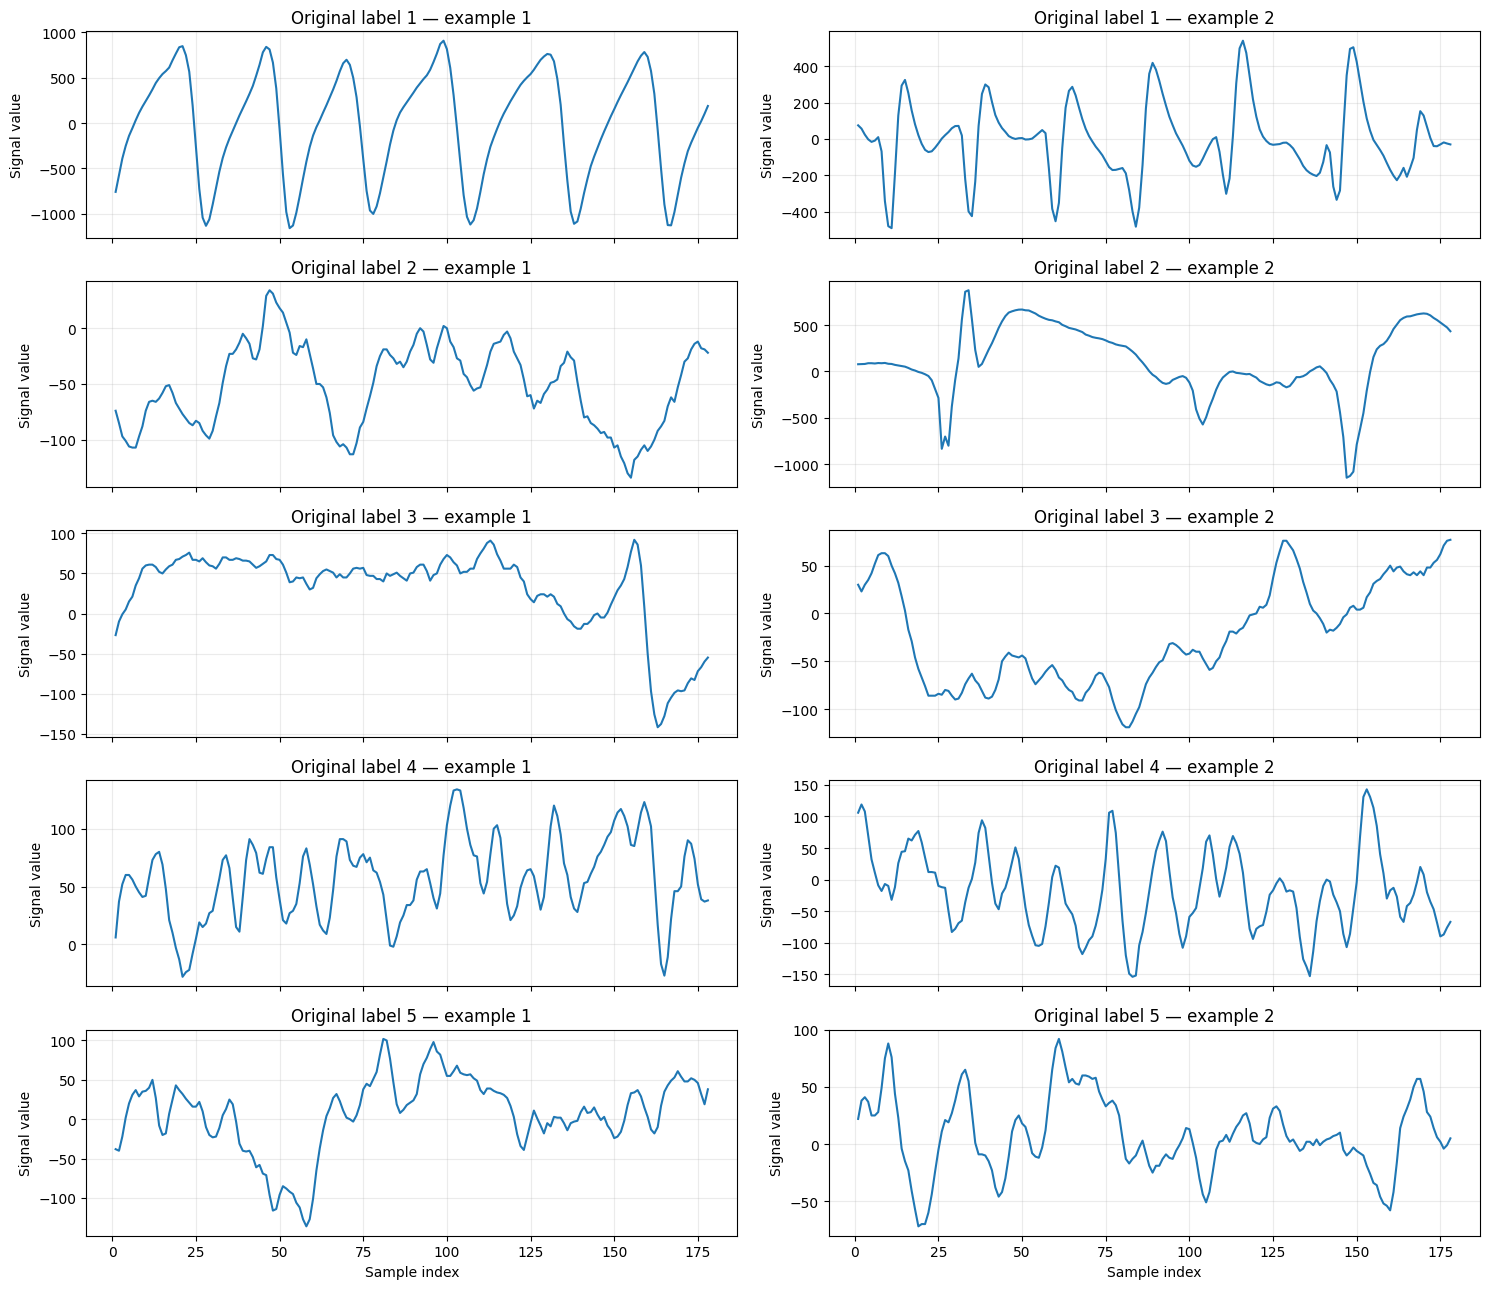

In [5]:
fig, axes = plt.subplots(5, 2, figsize=(15, 13), sharex=True)
for label in sorted(df["y"].dropna().unique()):
    examples = df[df["y"] == label].sample(
        n=min(2, int((df["y"] == label).sum())), random_state=SEED
    )
    for j, (_, row) in enumerate(examples.iterrows()):
        ax = axes[int(label) - 1, j]
        ax.plot(np.arange(1, 179), row[signal_cols].astype(float).values)
        ax.set_title(f"Original label {label} — example {j+1}")
        ax.set_ylabel("Signal value")
        ax.grid(alpha=0.25)
for ax in axes[-1, :]:
    ax.set_xlabel("Sample index")
plt.tight_layout()
plt.show()

## Part B — Leakage-safe train/validation/test split

We use `StratifiedGroupKFold` so every segment from a given recording stays in the same split. This approximates a 60%/20%/20% split by recording while attempting to preserve the seizure proportion.

### Cell 6 — Split by recording ID and verify no leakage

In [6]:
X_raw = df[signal_cols].astype(float)
y = df["seizure"].astype(int)
groups = df["recording_id"]

outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(outer_cv.split(X_raw, y, groups=groups))

X_trainval = X_raw.iloc[trainval_idx]
y_trainval = y.iloc[trainval_idx]
groups_trainval = groups.iloc[trainval_idx]

inner_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_rel, val_rel = next(
    inner_cv.split(X_trainval, y_trainval, groups=groups_trainval)
)
train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

X_train, y_train = X_raw.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X_raw.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X_raw.iloc[test_idx], y.iloc[test_idx]

g_train = set(groups.iloc[train_idx])
g_val = set(groups.iloc[val_idx])
g_test = set(groups.iloc[test_idx])

assert g_train.isdisjoint(g_val)
assert g_train.isdisjoint(g_test)
assert g_val.isdisjoint(g_test)

def split_summary(name, idx):
    part = df.iloc[idx]
    return {
        "Split": name,
        "Rows": len(part),
        "Recordings": part["recording_id"].nunique(),
        "Seizure rows": int(part["seizure"].sum()),
        "Seizure %": round(part["seizure"].mean() * 100, 2)
    }

split_table = pd.DataFrame([
    split_summary("Train", train_idx),
    split_summary("Validation", val_idx),
    split_summary("Test", test_idx)
])
display(split_table)
print("Recording overlap counts:",
      {"train-validation": len(g_train & g_val),
       "train-test": len(g_train & g_test),
       "validation-test": len(g_val & g_test)})

,Split,Rows,Recordings,Seizure rows,Seizure %
0,Train,6900,300,713,10.33
1,Validation,2300,100,782,34.00
2,Test,2300,100,805,35.00


Recording overlap counts: {'train-validation': 0, 'train-test': 0, 'validation-test': 0}


**Part B question — written answer**

A random row split could put neighbouring chunks from the same recording in both training and test sets. Shared recording-specific characteristics can make the test set easier and inflate performance. Grouping by recording reduces this leakage. However, the dataset has no patient IDs, so the same person may still contribute recordings to different splits.

## Part C — Baseline and comparison models

The baseline is logistic regression on standardised raw samples. We compare tree-based models on raw samples and engineered segment-level features. All preprocessing pipelines are fitted using training data only.

### Cell 7 — Build engineered features

In [7]:
def extract_features(frame):
    x = frame[signal_cols].to_numpy(dtype=float)
    out = pd.DataFrame(index=frame.index)
    out["mean"] = np.mean(x, axis=1)
    out["std"] = np.std(x, axis=1)
    out["minimum"] = np.min(x, axis=1)
    out["maximum"] = np.max(x, axis=1)
    out["range"] = np.ptp(x, axis=1)
    out["energy"] = np.mean(x ** 2, axis=1)
    out["zero_crossings"] = np.sum((x[:, :-1] * x[:, 1:]) < 0, axis=1)
    out["line_length"] = np.sum(np.abs(np.diff(x, axis=1)), axis=1)
    return out

X_eng = extract_features(df)
X_eng_train = X_eng.iloc[train_idx]
X_eng_val = X_eng.iloc[val_idx]
X_eng_test = X_eng.iloc[test_idx]
display(X_eng_train.head())
print("Engineered feature count:", X_eng.shape[1])

,mean,std,minimum,maximum,range,energy,zero_crossings,line_length
0,-16.910112,95.710958,-281.0,229.0,510.0,9446.539326,23,5700.0
3,-68.910112,15.923723,-105.0,-22.0,83.0,5002.168539,0,1072.0
4,-6.651685,38.693001,-103.0,78.0,181.0,1541.393258,27,2738.0
5,14.488764,48.943012,-91.0,122.0,213.0,2605.342697,14,2220.0
7,-32.544944,37.104782,-118.0,39.0,157.0,2435.938202,5,858.0


Engineered feature count: 8


### Cell 8 — Train five models

In [8]:
models = {
    "Logistic Regression (raw)": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    ),
    "Random Forest (raw)": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=250, min_samples_leaf=2, class_weight="balanced",
            n_jobs=-1, random_state=SEED
        )
    ),
    "Extra Trees (raw)": make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesClassifier(
            n_estimators=250, min_samples_leaf=2, class_weight="balanced",
            n_jobs=-1, random_state=SEED
        )
    ),
    "Gradient Boosting (raw)": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.1, random_state=SEED
        )
    ),
    "Extra Trees (engineered)": make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesClassifier(
            n_estimators=250, min_samples_leaf=2, class_weight="balanced",
            n_jobs=-1, random_state=SEED
        )
    )
}

fitted_models = {}
val_probabilities = {}

for name, model in models.items():
    if "engineered" in name:
        model.fit(X_eng_train, y_train)
        probs = model.predict_proba(X_eng_val)[:, 1]
    else:
        model.fit(X_train, y_train)
        probs = model.predict_proba(X_val)[:, 1]
    fitted_models[name] = model
    val_probabilities[name] = probs
    print("Finished:", name)

Finished: Logistic Regression (raw)
Finished: Random Forest (raw)
Finished: Extra Trees (raw)
Finished: Gradient Boosting (raw)
Finished: Extra Trees (engineered)


### Cell 9 — Validation metrics at threshold 0.5

In [9]:
def calculate_metrics(y_true, probabilities, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities)
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, predictions),
        "Sensitivity": tp / (tp + fn) if tp + fn else 0.0,
        "Specificity": tn / (tn + fp) if tn + fp else 0.0,
        "PPV": tp / (tp + fp) if tp + fp else 0.0,
        "NPV": tn / (tn + fn) if tn + fn else 0.0,
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Brier score": brier_score_loss(y_true, probabilities),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn)
    }

validation_rows = []
for name, probs in val_probabilities.items():
    row = calculate_metrics(y_val, probs, threshold=0.5)
    row["Model"] = name
    validation_rows.append(row)
validation_results = pd.DataFrame(validation_rows).set_index("Model")
display(validation_results.round(4).sort_values("PR-AUC", ascending=False))

,Threshold,Accuracy,Sensitivity,Specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier score,TP,FP,TN,FN
Model,,,,,,,,,,,,,
Extra Trees (raw),0.5,0.9287,0.7903,1.0000,1.0000,0.9025,0.9925,0.9874,0.0510,618,0,1518,164
Extra Trees (engineered),0.5,0.9561,0.9041,0.9829,0.9645,0.9521,0.9917,0.9860,0.0336,707,26,1492,75
Gradient Boosting (raw),0.5,0.9296,0.7967,0.9980,0.9952,0.9050,0.9917,0.9856,0.0644,623,3,1515,159
Random Forest (raw),0.5,0.9213,0.7698,0.9993,0.9983,0.8939,0.9904,0.9837,0.0611,602,1,1517,180
Logistic Regression (raw),0.5,0.6317,0.3734,0.7648,0.4499,0.7032,0.4860,0.4994,0.2540,292,357,1161,490


### Cell 10 — Confusion matrices and ROC curves

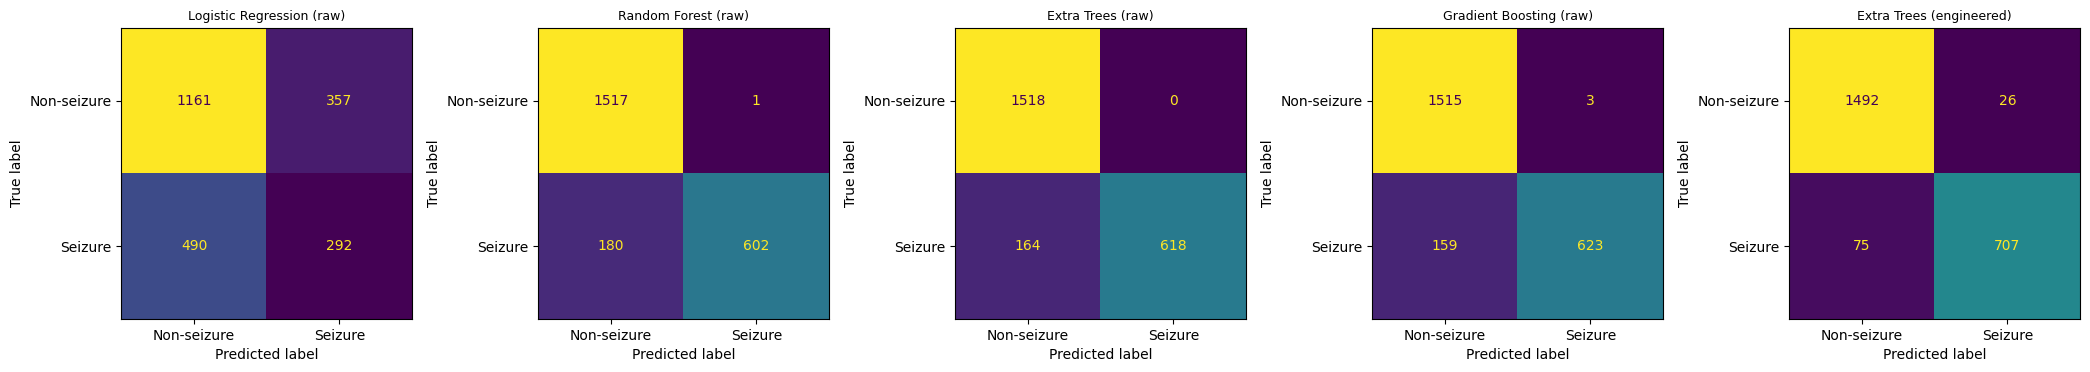

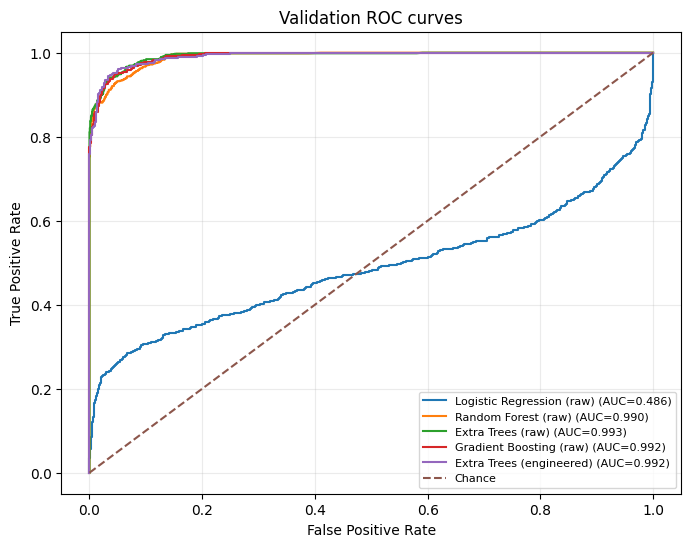

In [10]:
fig, axes = plt.subplots(1, len(fitted_models), figsize=(21, 4))
for ax, (name, probs) in zip(axes, val_probabilities.items()):
    preds = (probs >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_val, preds, labels=[0, 1],
        display_labels=["Non-seizure", "Seizure"], colorbar=False, ax=ax
    )
    ax.set_title(name, fontsize=9)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name, probs in val_probabilities.items():
    fpr, tpr, _ = roc_curve(y_val, probs)
    auc = roc_auc_score(y_val, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC curves")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.show()

### Cell 11 — Calibration plots and Brier scores

Baseline: Logistic Regression (raw)
Best model by validation PR-AUC: Extra Trees (raw)


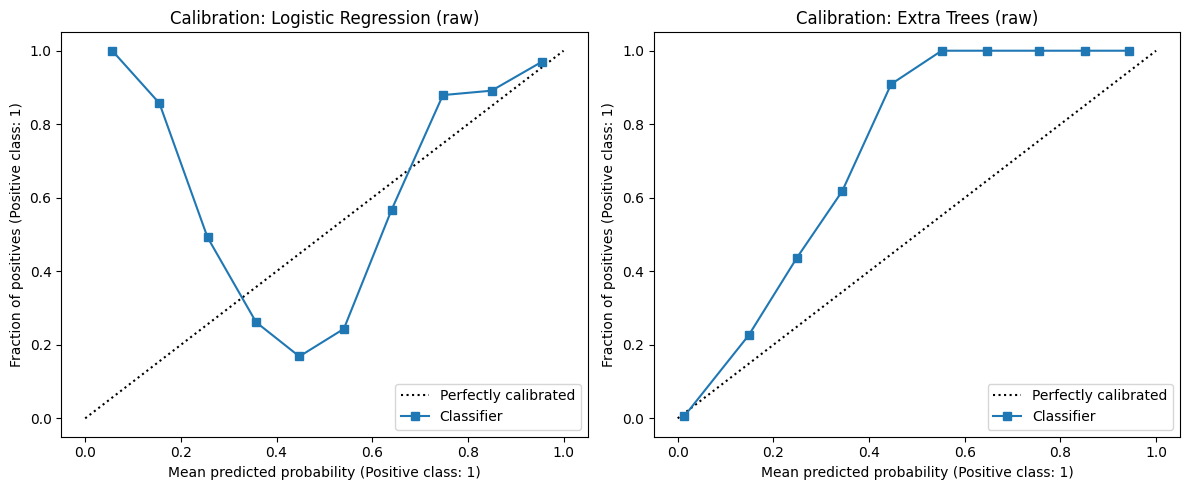

Baseline Brier score: 0.254
Selected model Brier score: 0.051


In [11]:
baseline_name = "Logistic Regression (raw)"
best_name = validation_results["PR-AUC"].idxmax()
print("Baseline:", baseline_name)
print("Best model by validation PR-AUC:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, [baseline_name, best_name]):
    CalibrationDisplay.from_predictions(
        y_val, val_probabilities[name], n_bins=10, strategy="uniform", ax=ax
    )
    ax.set_title(f"Calibration: {name}")
plt.tight_layout()
plt.show()

print("Baseline Brier score:",
      round(brier_score_loss(y_val, val_probabilities[baseline_name]), 4))
print("Selected model Brier score:",
      round(brier_score_loss(y_val, val_probabilities[best_name]), 4))

**Part C questions — written answer**

Use the validation table to state whether raw samples or engineered features worked better in this run. Do not assume one always wins. Engineered features such as standard deviation, range, and line length are relatively easy to explain because they summarise signal variability; energy summarises the average squared signal magnitude.

## Part D — Threshold selection

Thresholds are selected only using validation data. The rule is to choose the **highest threshold that still achieves at least 95% validation sensitivity**. This prioritises sensitivity while reducing false alarms among thresholds meeting the target.

### Cell 12 — Select threshold

In [12]:
best_val_probs = val_probabilities[best_name]
threshold_candidates = np.unique(np.concatenate(([0.0], best_val_probs, [1.0])))

eligible = []
for t in threshold_candidates:
    m = calculate_metrics(y_val, best_val_probs, float(t))
    if m["Sensitivity"] >= 0.95:
        eligible.append((float(t), m))

if eligible:
    threshold = max(eligible, key=lambda item: item[0])[0]
    threshold_rule_met = True
else:
    # Explicit fallback if the requested sensitivity cannot be achieved.
    threshold = max(
        (float(t) for t in threshold_candidates),
        key=lambda t: calculate_metrics(y_val, best_val_probs, t)["Sensitivity"]
    )
    threshold_rule_met = False

selected_val_metrics = calculate_metrics(y_val, best_val_probs, threshold)
print("Selected model:", best_name)
print("Selected threshold:", threshold)
print("95% sensitivity rule met:", threshold_rule_met)
if not threshold_rule_met:
    print("WARNING: No tested threshold reached 95% validation sensitivity; "
          "the fallback maximises validation sensitivity.")
display(pd.DataFrame([selected_val_metrics]).round(4))

Selected model: Extra Trees (raw)
Selected threshold: 0.19927024893056325
95% sensitivity rule met: True


,Threshold,Accuracy,Sensitivity,Specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier score,TP,FP,TN,FN
0,0.1993,0.9461,0.9501,0.944,0.8973,0.9735,0.9925,0.9874,0.051,743,85,1433,39


### Cell 13 — Compare raw and engineered features

,Sensitivity,Specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier score
Model,,,,,,,
Logistic Regression (raw),0.3734,0.7648,0.4499,0.7032,0.4860,0.4994,0.2540
Extra Trees (raw),0.7903,1.0000,1.0000,0.9025,0.9925,0.9874,0.0510
Extra Trees (engineered),0.9041,0.9829,0.9645,0.9521,0.9917,0.9860,0.0336


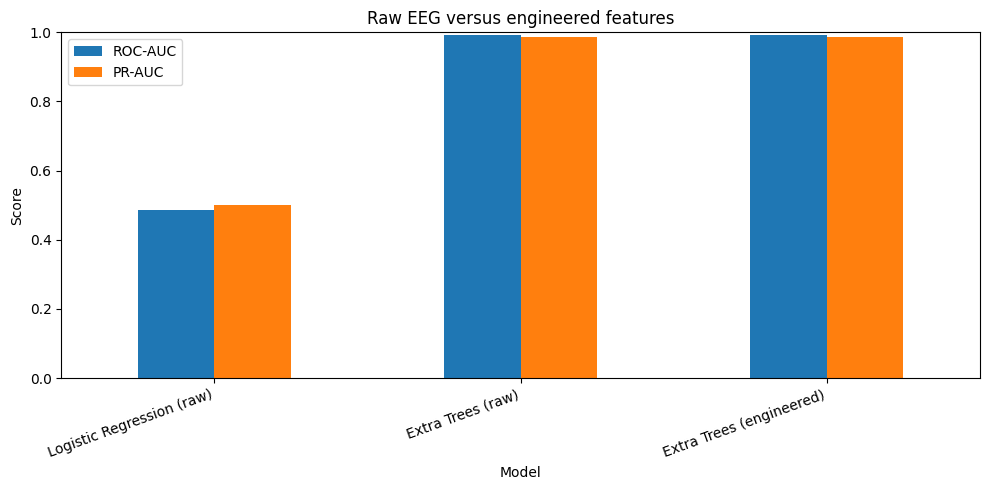

In [13]:
feature_comparison = validation_results.loc[
    ["Logistic Regression (raw)", "Extra Trees (raw)", "Extra Trees (engineered)"],
    ["Sensitivity", "Specificity", "PPV", "NPV", "ROC-AUC", "PR-AUC", "Brier score"]
]
display(feature_comparison.round(4))
feature_comparison[["ROC-AUC", "PR-AUC"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1),
    title="Raw EEG versus engineered features"
)
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Part D questions — written answer**

- A missed seizure segment can be costly in a screening workflow, so the threshold rule prioritises sensitivity. False alarms also matter because they can cause alert fatigue.
- **PPV** estimates the fraction of flagged segments that are true seizure segments. At a threshold with PPV 0.70, for example, about 70 of 100 flagged segments would be true positives in a population with the same characteristics as the evaluated data.
- A higher ROC-AUC does not guarantee better performance at a chosen threshold. ROC-AUC measures ranking across thresholds, whereas the confusion matrix and threshold-specific metrics describe one operating point.

## Part E — Final test evaluation

The test set is evaluated after selecting the model and threshold. Do not use these test results to tune the model or threshold.

### Cell 14 — Evaluate selected model once on the test set

Selected model: Extra Trees (raw)
Fixed validation-selected threshold: 0.19927024893056325


,Threshold,Accuracy,Sensitivity,Specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier score,TP,FP,TN,FN
0,0.1993,0.9287,0.9863,0.8977,0.8384,0.9919,0.9876,0.9757,0.0497,794,153,1342,11


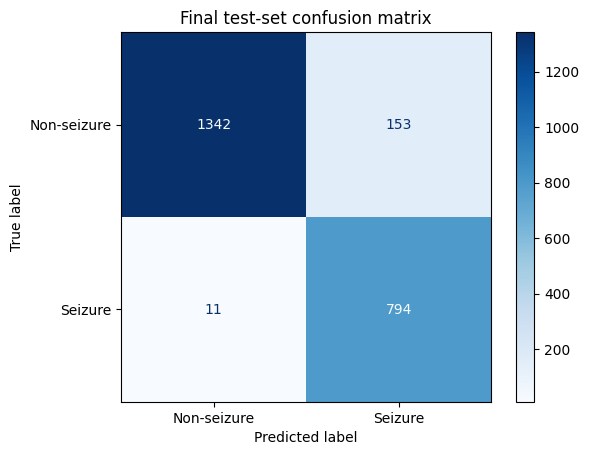

In [14]:
selected_model = fitted_models[best_name]
if "engineered" in best_name:
    test_probabilities = selected_model.predict_proba(X_eng_test)[:, 1]
else:
    test_probabilities = selected_model.predict_proba(X_test)[:, 1]

test_results = calculate_metrics(y_test, test_probabilities, threshold)
test_predictions = (test_probabilities >= threshold).astype(int)

print("Selected model:", best_name)
print("Fixed validation-selected threshold:", threshold)
display(pd.DataFrame([test_results]).round(4))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1],
    display_labels=["Non-seizure", "Seizure"], cmap="Blues"
)
plt.title("Final test-set confusion matrix")
plt.show()

### Cell 15 — False-positive and false-negative analysis by original label

False positives by original non-seizure label:


,FP count
y,
2,99
3,23
4,31


False negatives by original label:


,FN count
y,
1,11


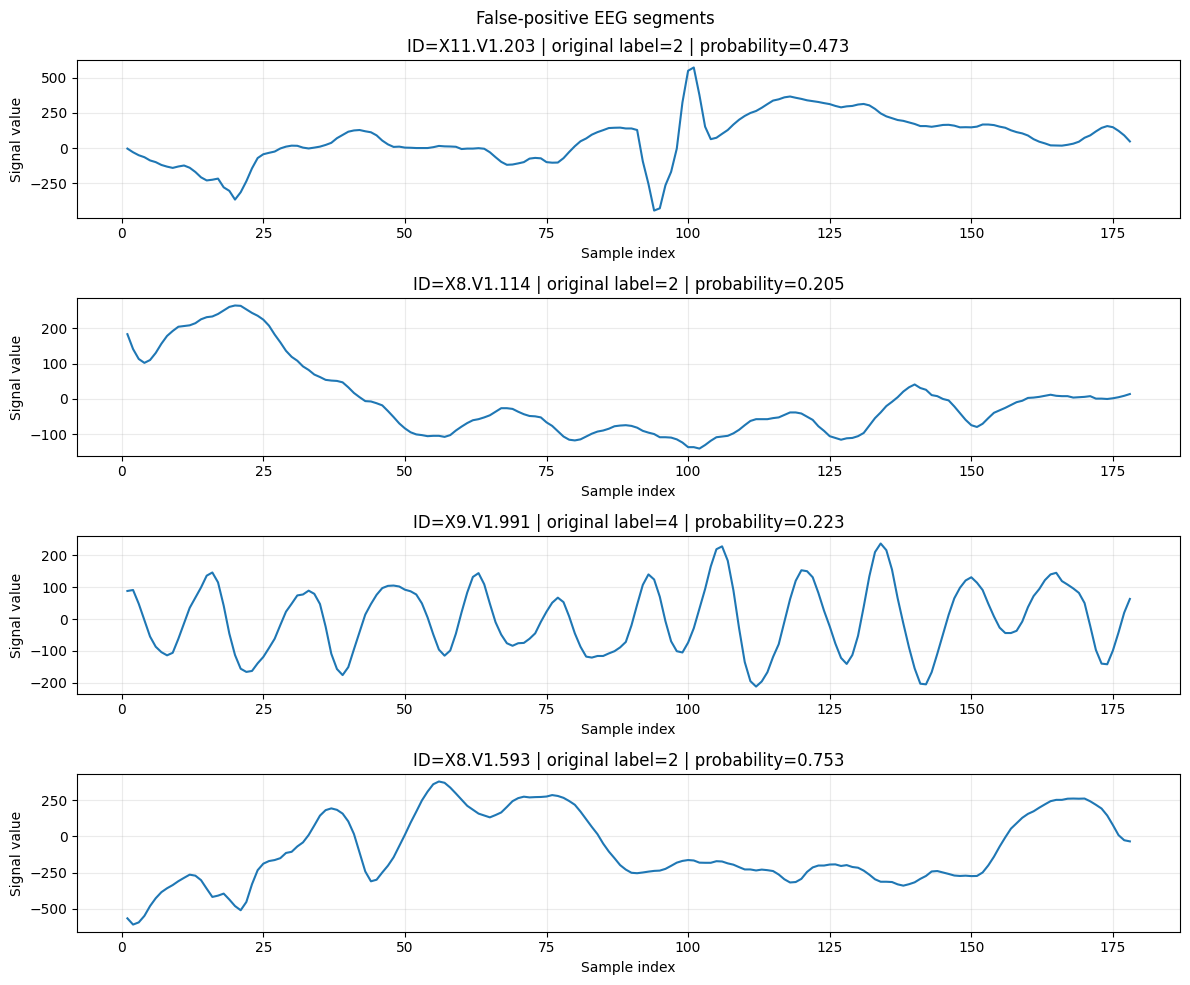

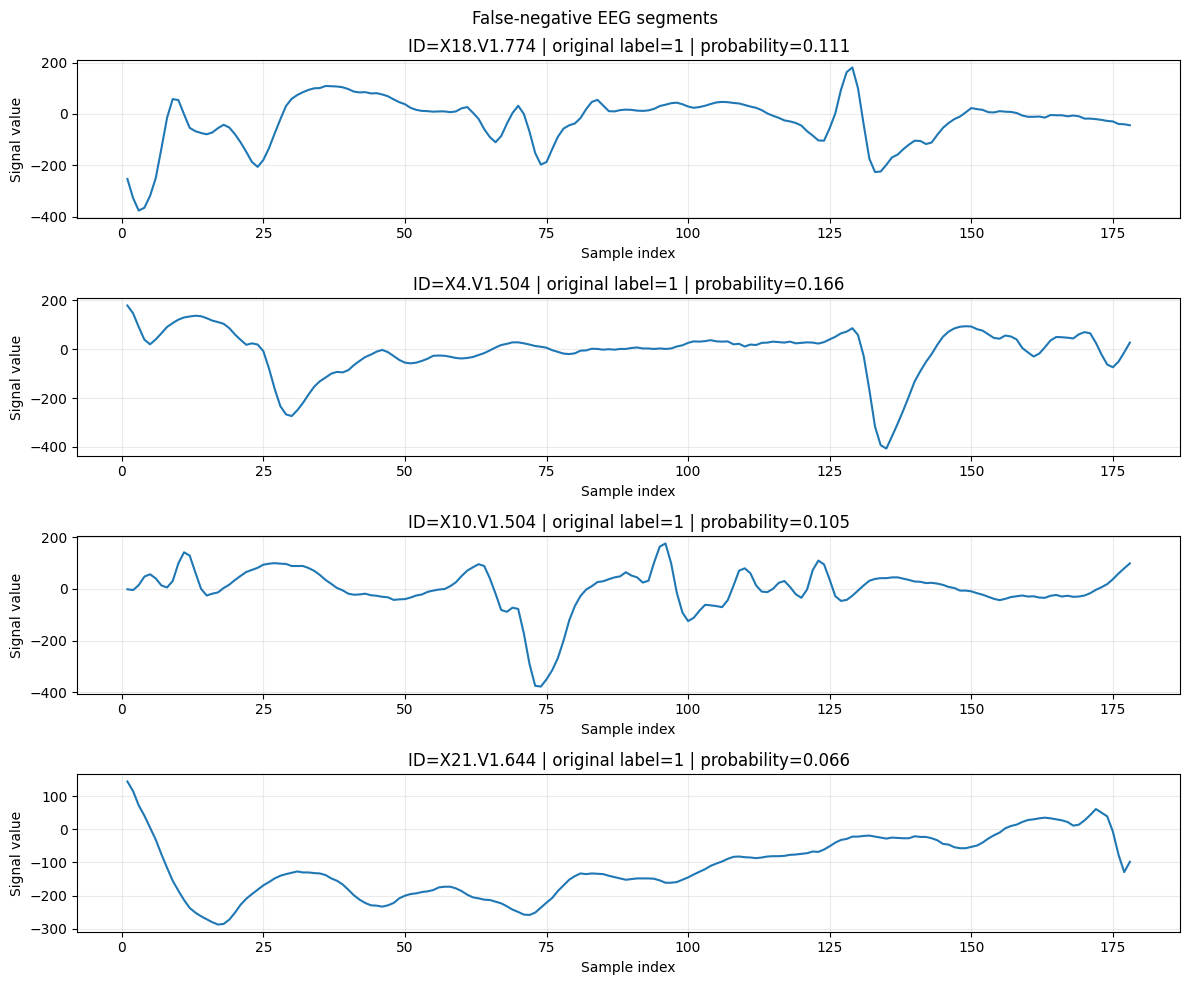

In [15]:
test_analysis = df.iloc[test_idx][["Unnamed", "recording_id", "y"] + signal_cols].copy()
test_analysis["true_seizure"] = y_test.to_numpy()
test_analysis["probability"] = test_probabilities
test_analysis["prediction"] = test_predictions

false_positives = test_analysis[
    (test_analysis["true_seizure"] == 0) & (test_analysis["prediction"] == 1)
]
false_negatives = test_analysis[
    (test_analysis["true_seizure"] == 1) & (test_analysis["prediction"] == 0)
]

print("False positives by original non-seizure label:")
display(false_positives["y"].value_counts().sort_index().rename("FP count").to_frame())
print("False negatives by original label:")
display(false_negatives["y"].value_counts().sort_index().rename("FN count").to_frame())

def plot_errors(errors, title, n=4):
    if errors.empty:
        print("No examples to plot:", title)
        return
    sample = errors.head(n)
    fig, axes = plt.subplots(len(sample), 1, figsize=(12, 2.5 * len(sample)))
    axes = np.atleast_1d(axes)
    for ax, (_, row) in zip(axes, sample.iterrows()):
        ax.plot(np.arange(1, 179), row[signal_cols].to_numpy(dtype=float))
        ax.set_title(
            f"ID={row['Unnamed']} | original label={row['y']} | "
            f"probability={row['probability']:.3f}"
        )
        ax.set_xlabel("Sample index")
        ax.set_ylabel("Signal value")
        ax.grid(alpha=0.25)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_errors(false_positives, "False-positive EEG segments")
plot_errors(false_negatives, "False-negative EEG segments")

### Cell 16 — Recording-level evaluation and recording-bootstrap confidence intervals

Recording-level evaluation (any segment above threshold):


,Threshold,Accuracy,Sensitivity,Specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier score,TP,FP,TN,FN
0,0.1993,0.85,1.0,0.7692,0.7,1.0,0.989,0.9783,0.0546,35,15,50,0


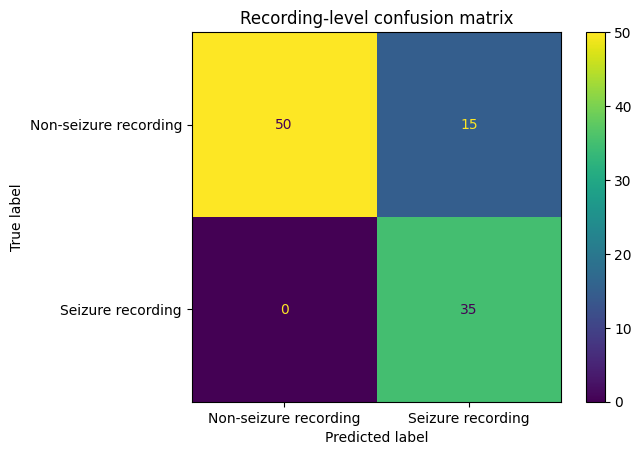

Recordings with most segment errors:


,errors,segments
recording_id,,
V1.814,23,23
V1.593,23,23
V1.412,22,23
V1.203,17,23
V1.991,15,23
V1.114,10,23
V1.603,9,23
V1.941,9,23
V1.243,8,23


Segment sensitivity: 0.9863; recording-bootstrap 95% CI: [0.9701, 0.9978]
Segment specificity: 0.8977; recording-bootstrap 95% CI: [0.8293, 0.9532]


In [16]:
# Each recording has a single original label in this dataset.
# Recording prediction rule: flag if ANY segment probability reaches the chosen threshold.
recording_results = test_analysis.groupby("recording_id").agg(
    true_label=("true_seizure", "first"),
    max_probability=("probability", "max"),
    segment_count=("prediction", "size"),
    flagged_segments=("prediction", "sum")
).reset_index()
recording_results["recording_prediction"] = (
    recording_results["max_probability"] >= threshold
).astype(int)

rec_metrics = calculate_metrics(
    recording_results["true_label"],
    recording_results["max_probability"],
    threshold
)
print("Recording-level evaluation (any segment above threshold):")
display(pd.DataFrame([rec_metrics]).round(4))
ConfusionMatrixDisplay.from_predictions(
    recording_results["true_label"], recording_results["recording_prediction"],
    labels=[0, 1],
    display_labels=["Non-seizure recording", "Seizure recording"]
)
plt.title("Recording-level confusion matrix")
plt.show()

print("Recordings with most segment errors:")
test_analysis["error"] = (
    test_analysis["true_seizure"] != test_analysis["prediction"]
).astype(int)
display(
    test_analysis.groupby("recording_id")["error"].agg(["sum", "count"])
    .rename(columns={"sum": "errors", "count": "segments"})
    .sort_values("errors", ascending=False).head(10)
)

# Bootstrap 95% CIs for segment-level sensitivity and specificity by resampling
# whole recordings, not individual rows. All segments from each sampled recording
# stay together. Sampling is with replacement.
rng = np.random.default_rng(SEED)
test_groups = list(test_analysis.groupby("recording_id"))
boot_sensitivity, boot_specificity = [], []
n_boot = 1000

for _ in range(n_boot):
    chosen = rng.integers(0, len(test_groups), size=len(test_groups))
    boot_parts = [test_groups[i][1] for i in chosen]
    boot = pd.concat(boot_parts, ignore_index=True)

    yt = boot["true_seizure"].to_numpy(dtype=int)
    yp = boot["prediction"].to_numpy(dtype=int)
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()

    if tp + fn > 0:
        boot_sensitivity.append(tp / (tp + fn))
    if tn + fp > 0:
        boot_specificity.append(tn / (tn + fp))

def ci_summary(values):
    return (
        float(np.percentile(values, 2.5)),
        float(np.percentile(values, 97.5))
    )

sens_ci = ci_summary(boot_sensitivity)
spec_ci = ci_summary(boot_specificity)

print(f"Segment sensitivity: {test_results['Sensitivity']:.4f}; "
      f"recording-bootstrap 95% CI: [{sens_ci[0]:.4f}, {sens_ci[1]:.4f}]")
print(f"Segment specificity: {test_results['Specificity']:.4f}; "
      f"recording-bootstrap 95% CI: [{spec_ci[0]:.4f}, {spec_ci[1]:.4f}]")

**Part E questions —  answer**

Use the displayed false-positive counts to identify which original non-seizure label produced the most false positives. Discuss plausible signal similarity rather than claiming a cause that the data cannot prove. If errors cluster in particular recordings, this may indicate recording-specific signal characteristics or that segments within a recording are not independent.

The recording-level evaluation uses the rule “flag the recording if any segment is positive.” It is a proxy analysis: because labels are inherited from the dataset's segment/recording structure, it does not validate clinical seizure detection over complete continuous EEG recordings.

## Part F — Reflection (150–250 words)

This experiment demonstrates how machine-learning models can prioritise EEG segments for further review, but strong performance on this dataset does not establish clinical usefulness. The dataset contains a limited number of recordings from a small number of people, and patient identifiers are unavailable. Although the split is performed by recording, segments from the same person could still appear across different splits. The dataset also uses selected segments and a class distribution that may not reflect routine hospital EEG review. In addition, the model does not incorporate clinical history, medications, symptoms, or other information a neurologist considers.

Before clinical consideration, the system would need external validation using independent, representative recordings from multiple hospitals, with patient-level separation and clinically reviewed reference labels. Performance should be evaluated across patient groups, recording conditions, seizure types, and realistic seizure prevalence. Prospective evaluation would also be needed to measure whether the tool improves review efficiency without increasing missed events or unnecessary workload.

The model should act only as a prioritisation aid. A qualified clinician must review flagged segments and make the final decision. Alert thresholds should balance missed events against false alarms, and alerts should be monitored to prevent fatigue. This model is educational and is not a diagnostic tool or a substitute for clinical assessment.

## Final results table
Validation rows are reported at threshold 0.5 for a consistent model comparison. The selected model is additionally reported on the test set at the threshold chosen from validation data.

### Cell 17 — Consolidated results table

In [17]:
metric_cols = [
    "Threshold", "Accuracy", "Sensitivity", "Specificity",
    "PPV", "NPV", "ROC-AUC", "PR-AUC", "Brier score"
]
final_table = validation_results[metric_cols].copy()
final_table["Evaluation"] = "Validation — threshold 0.5"

selected_val_row = pd.DataFrame([{
    **calculate_metrics(y_val, val_probabilities[best_name], threshold),
    "Evaluation": "Validation — selected threshold"
}], index=[best_name + " (selected threshold)"])[metric_cols + ["Evaluation"]]

test_row = pd.DataFrame([{
    **{k: test_results[k] for k in metric_cols},
    "Evaluation": "Final test — selected threshold"
}], index=[best_name + " (test)"])

final_table = pd.concat([final_table, selected_val_row, test_row])
display(final_table.round(4))

,Threshold,Accuracy,Sensitivity,Specificity,PPV,NPV,ROC-AUC,PR-AUC,Brier score,Evaluation
Logistic Regression (raw),0.5000,0.6317,0.3734,0.7648,0.4499,0.7032,0.4860,0.4994,0.2540,Validation — threshold 0.5
Random Forest (raw),0.5000,0.9213,0.7698,0.9993,0.9983,0.8939,0.9904,0.9837,0.0611,Validation — threshold 0.5
Extra Trees (raw),0.5000,0.9287,0.7903,1.0000,1.0000,0.9025,0.9925,0.9874,0.0510,Validation — threshold 0.5
Gradient Boosting (raw),0.5000,0.9296,0.7967,0.9980,0.9952,0.9050,0.9917,0.9856,0.0644,Validation — threshold 0.5
Extra Trees (engineered),0.5000,0.9561,0.9041,0.9829,0.9645,0.9521,0.9917,0.9860,0.0336,Validation — threshold 0.5
Extra Trees (raw) (selected threshold),0.1993,0.9461,0.9501,0.9440,0.8973,0.9735,0.9925,0.9874,0.0510,Validation — selected threshold
Extra Trees (raw) (test),0.1993,0.9287,0.9863,0.8977,0.8384,0.9919,0.9876,0.9757,0.0497,Final test — selected threshold
